## Question 1. Sinusoidal Positional Encoding: Mathematical Derivation and Implementation

(a) $pos$ is the zero-based token index, $i$ is the sine/cosine pair index ($0\le i<d/2$), and $d$ is the model width. With $\omega_i=10000^{-2i/d}$,

$$
[PE(pos,2i),\,PE(pos,2i+1)]=[\sin(pos\cdot\omega_i),\,\cos(pos\cdot\omega_i)].
$$

A larger $i$ makes $\omega_i$ smaller, so early columns vary quickly and later columns vary slowly. The wavelength is $\lambda_i=2\pi/\omega_i=2\pi\cdot 10000^{2i/d}$.


The same frequency is $\omega_i=1/10000^{2i/d}$. The dot in $pos\cdot\omega_i$ is multiplication, so sine and cosine each take one argument. Pair $i$ fills columns $2i$ and $2i+1$.

(c) Code Execution

In [3]:

import numpy as np
import matplotlib.pyplot as plt

**Encoder.** Each row is one token position. Even columns are sine and odd columns are cosine. An odd width keeps the final sine and drops the unpaired cosine.

In [7]:
def sinusoidal_positional_encoding(seq_len, d_model):
    """Return PE of shape (seq_len, d_model), including odd widths."""
    if seq_len < 0 or d_model < 1:
        raise ValueError("seq_len must be nonnegative and d_model positive")
    positions = np.arange(seq_len, dtype=float)[:, None]
    pair_indices = np.arange(0, d_model, 2, dtype=float)
    angles = positions / (10000.0 ** (pair_indices[None, :] / d_model))
    pe = np.zeros((seq_len, d_model), dtype=float)
    pe[:, 0::2] = np.sin(angles)
    pe[:, 1::2] = np.cos(angles[:, : pe[:, 1::2].shape[1]])
    return pe

**Check a small encoding.** For width 4, position 1 is $[\sin 1,\ \cos 1,\ \sin 0.01,\ \cos 0.01]$.

In [6]:
pe_manual = sinusoidal_positional_encoding(3, 4)
print(np.round(pe_manual, 6))
np.testing.assert_allclose(
    pe_manual[1],
    [np.sin(1), np.cos(1), np.sin(0.01), np.cos(0.01)],
)
print("Position 1 matches the formula.")

[[ 0.        1.        0.        1.      ]
 [ 0.841471  0.540302  0.01      0.99995 ]
 [ 0.909297 -0.416147  0.019999  0.9998  ]]
Position 1 matches the formula.


**Heatmap.** Encode 20 positions with width 16. Left columns oscillate quickly; right columns change slowly.

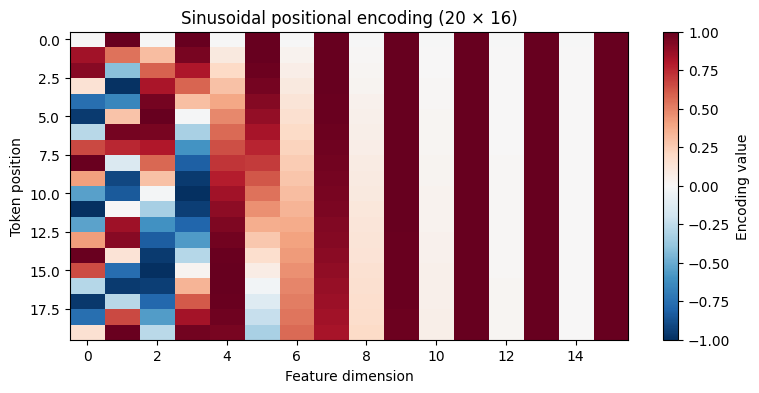

In [9]:
pe = sinusoidal_positional_encoding(20, 16)
assert pe.shape == (20, 16)

fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(pe, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
ax.set(
    xlabel="Feature dimension",
    ylabel="Token position",
    title="Sinusoidal positional encoding (20 × 16)",
)
fig.colorbar(im, ax=ax, label="Encoding value")
plt.show()

(d) **Periodicity.** Sine and cosine repeat. Pair $i$ returns to the same value every wavelength $\lambda_i=2\pi\cdot 10000^{2i/d}$ positions.

**Different frequencies.** A small $i$ is a short wavelength, so nearby positions get very different values. A large $i$ is a long wavelength, so the feature still changes between distant positions. The short waves separate neighbors; the long waves keep far tokens apart.

**Relative position.** For a fixed shift $\Delta$,

$$\left[\sin((pos+\Delta)\cdot\omega_i),\;\cos((pos+\Delta)\cdot\omega_i)\right]$$

is a fixed rotation of the pair at $pos$. The offset $\Delta$ can therefore be read from the features already stored at $pos$.